# Fundamental Valuation from SEC XBRL Financials

A credit analyst needs a market-consistent view of what a company is worth, because equity value is the cushion that sits above the debt. Comparable-company multiples are the everyday tool, usually built from an expensive vendor database. Every U.S. filer, though, now tags its statements in machine-readable XBRL. This notebook builds the fundamentals panel from those filings and asks how much better than sector comps a model can price a company.

**What it does.** It builds a clean fundamentals panel for about 900 large U.S.-headquartered non-financial companies directly from SEC XBRL filings, and models each company's price-to-sales multiple from its fundamentals.

Sector comps, OLS, Elastic Net and LightGBM are compared out of fold, rich and cheap names are flagged, and the notebook checks whether last year's "cheap" names actually outperformed.

**Data.** The SEC EDGAR XBRL *frames* API (one call returns one line item for every filer), company submissions (SIC codes), the SEC ticker map, and Yahoo Finance prices for market capitalisation and forward returns.

**Methods.** ETL and tag harmonisation in DuckDB SQL, and ratio engineering (growth, margins, cash conversion, leverage, Altman Z″).

Sector-median comps, OLS, Elastic Net and LightGBM are compared with K-fold and leave-sector-out cross-validation, explained with TreeSHAP, and followed by a one-year forward-return test by valuation residual.

**Key output.** Out-of-fold valuation error by model, feature attributions, the richest and cheapest names today, and forward returns by residual quintile.

## 1. Why value companies from XBRL

A counterparty or corporate-credit analyst constantly needs a **market-consistent view of a company's value**: equity value is the cushion above the debt in a structural credit model, and a stock that looks richly valued against its fundamentals has more room to fall. Comparable-company multiples are the everyday tool, and they are usually built from a vendor database.

Since 2009 every SEC filer tags its statements in **XBRL**, so the raw data is public and machine-readable. The work is in the ETL: the same concept appears under different tags (revenue alone has at least four common ones), fiscal years end in different months, and some values are missing or mis-scaled.

This notebook builds the panel from scratch and then asks a modelling question: how much better than **sector-median comps** can a model price a company from its fundamentals?

The target is $\log(\text{market cap}/\text{Sales})$, the price-to-sales multiple, which works for loss-making companies, unlike P/E. P/S would be cleaner across capital structures, but it needs total debt, and debt tags are missing for about half of XBRL filers (see the coverage table in Section 3).

A wrong debt figure would make a company look cheap for no economic reason, so the notebook models P/S and gives the model book leverage (liabilities/assets, available for nearly everyone) as a feature instead. Banks, insurers and REITs are excluded because sales multiples are not meaningful for them; they need price-to-book models.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import lightgbm as lgb
import yfinance as yf
from sklearn.linear_model import ElasticNetCV, LinearRegression
from sklearn.model_selection import GroupKFold, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEC_USER_AGENT = os.getenv("SEC_USER_AGENT", "").strip()
if not SEC_USER_AGENT:
    raise RuntimeError(
        "SEC_USER_AGENT not found in .env (SEC requires 'Name email@domain' in"
        " the User-Agent)."
    )
SEC_HEADERS = {
    "User-Agent": SEC_USER_AGENT,
    "Accept-Encoding": "gzip, deflate",
}

FY_NOW, FY_BACKTEST = (
    2025,
    2024,
)  # fiscal-year frames used for today's model and for the forward test
# USD; keeps the universe to established companies
MIN_REVENUE = 500e6
MAX_COMPANIES = 1_000
BACKTEST_PRICE_DATE, BACKTEST_END_DATE = "2025-04-30", "2026-04-30"
SEED = 11

print(
    f"duckdb {duckdb.__version__} · lightgbm {lgb.__version__} · yfinance"
    f" {yf.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

duckdb 1.5.6 · lightgbm 4.7.0 · yfinance 1.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


MODEL_COLORS = {
    "Sector median (comps)": "#9c9b97",
    "OLS": PALETTE[0],
    "Elastic Net": PALETTE[2],
    "LightGBM": PALETTE[1],
}


def sec_get(url, pause=0.12):
    """
    SEC fair-access policy: identify yourself and stay under 10 requests per
    second.
    """
    time.sleep(pause)
    r = requests.get(url, headers=SEC_HEADERS, timeout=60)
    r.raise_for_status()
    return r.json()

## 3. ETL: XBRL frames into DuckDB

The **frames API** (`data.sec.gov/api/xbrl/frames/{taxonomy}/{tag}/{unit}/{period}.json`) returns one value per company for a tag and a calendar period: `CY2025` for a fiscal-year flow, `CY2025Q4I` for a balance-sheet value at the end of 2025. Fiscal years are mapped to the calendar year they mostly cover. About 25 tags × 4 periods cover the whole market in roughly 100 requests.

Each concept lists alternative tags in priority order. The SQL below takes the first non-missing one per company, the same choice an analyst makes by hand.

In [3]:
CONCEPTS = {  # concept: (kind, [tags in priority order])
    "revenue": (
        "dur",
        [
            "Revenues",
            "RevenueFromContractWithCustomerExcludingAssessedTax",
            "SalesRevenueNet",
            "RevenueFromContractWithCustomerIncludingAssessedTax",
        ],
    ),
    "gross_profit": ("dur", ["GrossProfit"]),
    "operating_income": ("dur", ["OperatingIncomeLoss"]),
    "net_income": ("dur", ["NetIncomeLoss", "ProfitLoss"]),
    "cfo": (
        "dur",
        [
            "NetCashProvidedByUsedInOperatingActivities",
            "NetCashProvidedByUsedInOperatingActivitiesContinuingOperations",
        ],
    ),
    "capex": (
        "dur",
        [
            "PaymentsToAcquirePropertyPlantAndEquipment",
            "PaymentsToAcquireProductiveAssets",
        ],
    ),
    "rnd": (
        "dur",
        [
            "ResearchAndDevelopmentExpense",
            "ResearchAndDevelopmentExpenseExcludingAcquiredInProcessCost",
        ],
    ),
    "interest_expense": (
        "dur",
        [
            "InterestExpense",
            "InterestExpenseNonoperating",
            "InterestExpenseDebt",
        ],
    ),
    "dna": (
        "dur",
        [
            "DepreciationDepletionAndAmortization",
            "DepreciationAndAmortization",
            "DepreciationAmortizationAndAccretionNet",
        ],
    ),
    "assets": ("inst", ["Assets"]),
    "liabilities": ("inst", ["Liabilities"]),
    "equity": (
        "inst",
        [
            "StockholdersEquity",
            "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest",
        ],
    ),
    "current_assets": ("inst", ["AssetsCurrent"]),
    "current_liabilities": ("inst", ["LiabilitiesCurrent"]),
    "cash": (
        "inst",
        [
            "CashAndCashEquivalentsAtCarryingValue",
            "CashCashEquivalentsRestrictedCashAndRestrictedCashEquivalents",
        ],
    ),
    "lt_debt": (
        "inst",
        [
            "LongTermDebtNoncurrent",
            "LongTermDebt",
            "LongTermDebtAndCapitalLeaseObligations",
        ],
    ),
    "st_debt": (
        "inst",
        ["LongTermDebtCurrent", "DebtCurrent", "ShortTermBorrowings"],
    ),
    "retained_earnings": ("inst", ["RetainedEarningsAccumulatedDeficit"]),
}


def fetch_frame(tag, period, taxonomy="us-gaap", unit="USD"):
    url = f"https://data.sec.gov/api/xbrl/frames/{taxonomy}/{tag}/{unit}/{period}.json"
    try:
        d = sec_get(url)
    except requests.HTTPError as err:
        if err.response is not None and err.response.status_code == 404:
            return pd.DataFrame()
        raise
    df = pd.DataFrame(d["data"])
    df["tag"], df["period"] = tag, period
    return df[
        ["cik", "entityName", "loc", "tag", "period", "end", "val", "accn"]
    ]


def fetch_all_frames():
    parts = []
    for fy in (FY_NOW, FY_BACKTEST, FY_BACKTEST - 1):
        for concept, (kind, tags) in CONCEPTS.items():
            if fy == FY_BACKTEST - 1 and concept != "revenue":
                # the earliest year is only needed for growth
                continue
            period = f"CY{fy}" if kind == "dur" else f"CY{fy}Q4I"
            for tag in tags:
                parts.append(
                    fetch_frame(tag, period).assign(
                        concept=concept, fy=fy, priority=tags.index(tag)
                    )
                )
    for period in (
        f"CY{FY_NOW + 1}Q2I",
        f"CY{FY_NOW + 1}Q1I",
        f"CY{FY_NOW}Q4I",
        f"CY{FY_BACKTEST + 1}Q1I",
        f"CY{FY_BACKTEST}Q4I",
    ):
        parts.append(
            fetch_frame(
                "EntityCommonStockSharesOutstanding",
                period,
                taxonomy="dei",
                unit="shares",
            ).assign(concept="shares", fy=0, priority=0)
        )
    return pd.concat(parts, ignore_index=True)


t0 = time.perf_counter()
facts = cached("xbrl_frames", fetch_all_frames, max_age_hours=24 * 7)
tickers = cached(
    "sec_tickers",
    lambda: pd.DataFrame(
        sec_get("https://www.sec.gov/files/company_tickers.json")
    )
    .T.rename(columns={"cik_str": "cik", "title": "name"})
    .astype({"cik": int}),
    max_age_hours=24 * 7,
)
print(
    f"{len(facts):,} XBRL facts · {facts['cik'].nunique():,} filers ·"
    f" {facts['tag'].nunique()} tags in {time.perf_counter() - t0:.0f}s"
)

con = duckdb.connect()
con.register("facts", facts)
# first ticker per CIK = the primary share class
con.register("tickers", tickers.drop_duplicates("cik"))
con.sql(
    """
CREATE OR REPLACE TABLE fundamentals AS
WITH ranked AS (
    SELECT cik, entityName, loc, concept, fy, val, "end",
           ROW_NUMBER() OVER (PARTITION BY cik, concept, fy ORDER BY priority, "end" DESC) AS rk
    FROM facts WHERE concept <> 'shares'
)
SELECT cik, fy, ANY_VALUE(entityName) AS name, ANY_VALUE(loc) AS loc, MAX("end") AS period_end,
"""
    + ",\n".join(
        f"       MAX(val) FILTER (WHERE concept = '{c}') AS {c}"
        for c in CONCEPTS
    )
    + """
FROM ranked WHERE rk = 1 GROUP BY cik, fy
"""
)
con.sql("""
CREATE OR REPLACE TABLE shares AS
SELECT cik, period, val AS shares, "end" FROM facts WHERE concept = 'shares'
""")
con.sql(
    "SELECT fy, COUNT(*) AS companies, COUNT(revenue) AS with_revenue,"
    " COUNT(equity) AS with_equity, COUNT(cfo) AS with_cfo, COUNT(lt_debt) AS"
    " with_lt_debt FROM fundamentals GROUP BY fy ORDER BY fy"
).df()

217,608 XBRL facts · 7,919 filers · 35 tags in 58s


,fy,companies,with_revenue,with_equity,with_cfo,with_lt_debt
0,2023,5344,5344,0,0,0
1,2024,6696,5095,6315,6264,3046
2,2025,6391,4699,6025,5877,2918


### Tag coverage

How often each revenue tag is the one chosen shows why harmonisation matters: no single tag covers the market.

In [4]:
con.sql(f"""
SELECT tag, COUNT(DISTINCT cik) AS filers
FROM facts WHERE concept = 'revenue' AND fy = {FY_NOW}
GROUP BY tag ORDER BY filers DESC
""").df()

,tag,filers
0,RevenueFromContractWithCustomerExcludingAssess...,2708
1,Revenues,2254
2,RevenueFromContractWithCustomerIncludingAssess...,660


## 4. Universe, sectors and prices

The universe is U.S.-headquartered non-financial filers with a ticker and revenue of at least $500m, capped at the 1,000 largest by revenue. Foreign issuers listed through ADRs are excluded: their cover-page share count is in ordinary shares (one ADR is often 5 or 10 of them), and some tag local-currency figures, which would mis-scale the multiple by an order of magnitude. SIC codes come from each company's submissions file and are grouped into 13 sectors. Market capitalisation is the latest close times the latest cover-page share count.

In [5]:
def sector_of(sic):
    s = int(sic) if pd.notna(sic) and str(sic).isdigit() else -1
    rules = [
        ((1300, 1399), "Energy"),
        ((2900, 2999), "Energy"),
        ((1000, 1499), "Materials & mining"),
        ((2830, 2836), "Healthcare"),
        ((3840, 3851), "Healthcare"),
        ((8000, 8099), "Healthcare"),
        ((3570, 3579), "Tech hardware & semis"),
        ((3600, 3699), "Tech hardware & semis"),
        ((3670, 3679), "Tech hardware & semis"),
        ((7370, 7379), "Software & IT services"),
        ((4800, 4899), "Communication & media"),
        ((2700, 2799), "Communication & media"),
        ((4900, 4999), "Utilities"),
        ((5000, 5999), "Retail & wholesale"),
        ((2000, 2199), "Consumer staples"),
        ((3710, 3716), "Autos & transport"),
        ((4000, 4799), "Autos & transport"),
        ((1500, 1799), "Industrials"),
        ((2200, 2399), "Consumer discretionary"),
        ((3940, 3949), "Consumer discretionary"),
        ((7000, 7999), "Consumer discretionary"),
        ((2400, 2899), "Materials & mining"),
        ((3000, 3399), "Materials & mining"),
        ((3400, 3999), "Industrials"),
        ((8100, 8999), "Business services"),
        ((100, 999), "Consumer staples"),
    ]
    for (a, b), name in rules:
        if a <= s <= b:
            return name
    return "Financials" if 6000 <= s <= 6799 else "Other"


cands = con.sql(f"""
SELECT f.cik, t.ticker, f.name, f.loc, f.revenue FROM fundamentals f JOIN tickers t USING (cik)
WHERE f.fy = {FY_NOW} AND f.revenue >= {MIN_REVENUE} AND f.loc LIKE 'US-%' 
ORDER BY f.revenue DESC LIMIT {int(MAX_COMPANIES * 1.6)}
""").df()


def fetch_sics():
    rows = []
    for cik in cands["cik"]:
        try:
            d = sec_get(
                f"https://data.sec.gov/submissions/CIK{int(cik):010d}.json"
            )
            rows.append({
                "cik": int(cik),
                "sic": d.get("sic"),
                "sic_desc": d.get("sicDescription"),
                "fye": d.get("fiscalYearEnd"),
            })
        except Exception:
            rows.append(
                {"cik": int(cik), "sic": None, "sic_desc": None, "fye": None}
            )
    return pd.DataFrame(rows)


sics = cached("sec_sic", fetch_sics, max_age_hours=24 * 30)
sics["sector"] = sics["sic"].map(sector_of)
universe = cands.merge(sics, on="cik", how="left")
universe = (
    universe[~universe["sector"].isin(["Financials", "Other"])]
    .head(MAX_COMPANIES)
    .reset_index(drop=True)
)
universe["yahoo"] = universe["ticker"].str.replace(".", "-", regex=False)
print(
    f"Universe: {len(universe)} U.S. non-financial companies across"
    f" {universe['sector'].nunique()} sectors"
)


def fetch_prices():
    out = []
    syms = universe["yahoo"].tolist()
    for i in range(0, len(syms), 200):
        px = yf.download(
            syms[i : i + 200],
            start="2025-04-01",
            auto_adjust=True,
            progress=False,
            threads=True,
        )["Close"]
        out.append(px)
    px = pd.concat(out, axis=1).copy()
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.index.name = "date"
    return px.reset_index()


prices = cached("yahoo_prices", fetch_prices).set_index("date").sort_index()
prices = prices[prices.index < pd.Timestamp.today().normalize()]
PRICE_DATE = prices.dropna(how="all").index.max()
print(
    f"Prices: {prices.notna().any().sum()} of {len(universe)} tickers · last"
    f" close {PRICE_DATE:%Y-%m-%d}"
)
universe.groupby("sector").agg(
    companies=("cik", "size"),
    median_revenue_bn=("revenue", lambda r: r.median() / 1e9),
).round(1)

Universe: 1000 U.S. non-financial companies across 13 sectors
Prices: 999 of 1000 tickers · last close 2026-10-16


,companies,median_revenue_bn
sector,,
Autos & transport,69,7.50
Business services,22,3.50
Communication & media,29,4.70
Consumer discretionary,114,4.60
Consumer staples,35,10.30
Energy,45,4.90
Healthcare,83,4.70
Industrials,134,4.50
Materials & mining,114,4.20


## 5. Features

| Group | Features |
|---|---|
| Size and growth | log revenue, revenue growth |
| Profitability | gross, operating and net margin, return on assets |
| Cash conversion | operating cash flow margin, capex intensity, free-cash-flow margin, R&D intensity |
| Balance sheet | debt/assets, net debt/EBITDA, interest coverage, current ratio, retained earnings/assets |
| Credit | Altman Z″ (the non-manufacturer version: working capital, retained earnings, EBIT and book equity, each over assets or liabilities) |

Ratios are winsorised at the 1st and 99th percentiles. Missing values are left missing for LightGBM, and for the linear models they are median-imputed with a missing-value indicator.

In [6]:
def latest_shares(periods):
    q = con.sql(f"""
        SELECT cik, ARG_MAX(shares, "end") AS shares FROM shares
        WHERE period IN ({", ".join(f"'{p}'" for p in periods)}) GROUP BY cik
    """).df()
    return q.set_index("cik")["shares"]


def build_panel(fy, price_date, share_periods):
    f = (
        con.sql(f"SELECT * FROM fundamentals WHERE fy = {fy}")
        .df()
        .set_index("cik")
    )
    prev = (
        con.sql(
            "SELECT cik, revenue AS revenue_prev FROM fundamentals WHERE fy ="
            f" {fy - 1}"
        )
        .df()
        .set_index("cik")
    )
    d = (
        universe.set_index("cik")[["ticker", "yahoo", "sector", "sic_desc"]]
        .join(f.drop(columns=["fy"]), how="inner")
        .join(prev)
    )
    d["shares"] = latest_shares(share_periods)
    px = prices.loc[:price_date].ffill().iloc[-1]
    d["price"] = d["yahoo"].map(px)
    d["mcap"] = d["price"] * d["shares"]
    debt = d[["lt_debt", "st_debt"]].sum(axis=1, min_count=1).fillna(0)
    ebitda = d["operating_income"] + d["dna"].fillna(0)
    feats = pd.DataFrame(index=d.index)
    feats["log revenue"] = np.log(d["revenue"])
    feats["revenue growth"] = d["revenue"] / d["revenue_prev"] - 1
    feats["gross margin"] = d["gross_profit"] / d["revenue"]
    feats["operating margin"] = d["operating_income"] / d["revenue"]
    feats["net margin"] = d["net_income"] / d["revenue"]
    feats["ROA"] = d["net_income"] / d["assets"]
    feats["CFO margin"] = d["cfo"] / d["revenue"]
    feats["capex intensity"] = d["capex"] / d["revenue"]
    feats["FCF margin"] = (d["cfo"] - d["capex"].fillna(0)) / d["revenue"]
    feats["R&D intensity"] = d["rnd"].fillna(0) / d["revenue"]
    feats["liabilities / assets"] = d["liabilities"] / d["assets"]
    feats["debt / assets"] = (
        debt.where(d[["lt_debt", "st_debt"]].notna().any(axis=1)) / d["assets"]
    )
    feats["net debt / EBITDA"] = ((debt - d["cash"].fillna(0)) / ebitda).where(
        ebitda > 0
    )
    feats["interest coverage"] = (
        d["operating_income"] / d["interest_expense"]
    ).where(d["interest_expense"] > 0)
    feats["current ratio"] = d["current_assets"] / d["current_liabilities"]
    feats["retained earnings / assets"] = d["retained_earnings"] / d["assets"]
    wc = (d["current_assets"] - d["current_liabilities"]) / d["assets"]
    feats["Altman Z''"] = (
        6.56 * wc
        + 3.26 * feats["retained earnings / assets"]
        + 6.72 * d["operating_income"] / d["assets"]
        + 1.05 * d["equity"] / d["liabilities"]
    )
    for c in feats.columns:
        if c != "log revenue":
            lo, hi = feats[c].quantile([0.01, 0.99])
            feats[c] = feats[c].clip(lo, hi)
    ok = d["mcap"].gt(0) & d["revenue"].gt(0)
    d["target"] = np.log((d["mcap"] / d["revenue"]).where(ok))
    ok &= d["target"].between(np.log(0.03), np.log(60))
    return d[ok], feats[ok]


meta_now, X_now = build_panel(
    FY_NOW,
    PRICE_DATE,
    [f"CY{FY_NOW + 1}Q2I", f"CY{FY_NOW + 1}Q1I", f"CY{FY_NOW}Q4I"],
)
FEATURES = list(X_now.columns)
print(
    f"Modelling panel FY{FY_NOW}: {len(meta_now)} companies ·"
    f" {len(FEATURES)} features · priced {PRICE_DATE:%Y-%m-%d}"
)

# Spot-check the ETL against well-known figures
check = meta_now[
    meta_now["ticker"].isin(["AAPL", "MSFT", "XOM", "WMT", "JNJ", "GOOGL"])
].set_index("ticker")[["name", "period_end", "revenue", "net_income", "mcap"]]
(
    check.assign(
        **{c: check[c] / 1e9 for c in ["revenue", "net_income", "mcap"]}
    )
    .assign(**{"P/S": check["mcap"] / check["revenue"]})
    .rename(
        columns={
            "revenue": "revenue $bn",
            "net_income": "net income $bn",
            "mcap": "mkt cap $bn",
        }
    )
    .round(1)
)

Modelling panel FY2025: 770 companies · 17 features · priced 2026-10-16


,name,period_end,revenue $bn,net income $bn,mkt cap $bn,P/S
ticker,,,,,,
WMT,WALMART INC.,2026-01-31,713.20,21.90,945.50,1.30
AAPL,Apple Inc.,2025-12-27,416.20,112.00,"5,012.50",12.00
MSFT,MICROSOFT CORPORATION,2025-12-31,281.70,101.80,"3,928.50",13.90
JNJ,Johnson & Johnson,2025-12-28,94.20,26.80,615.90,6.50


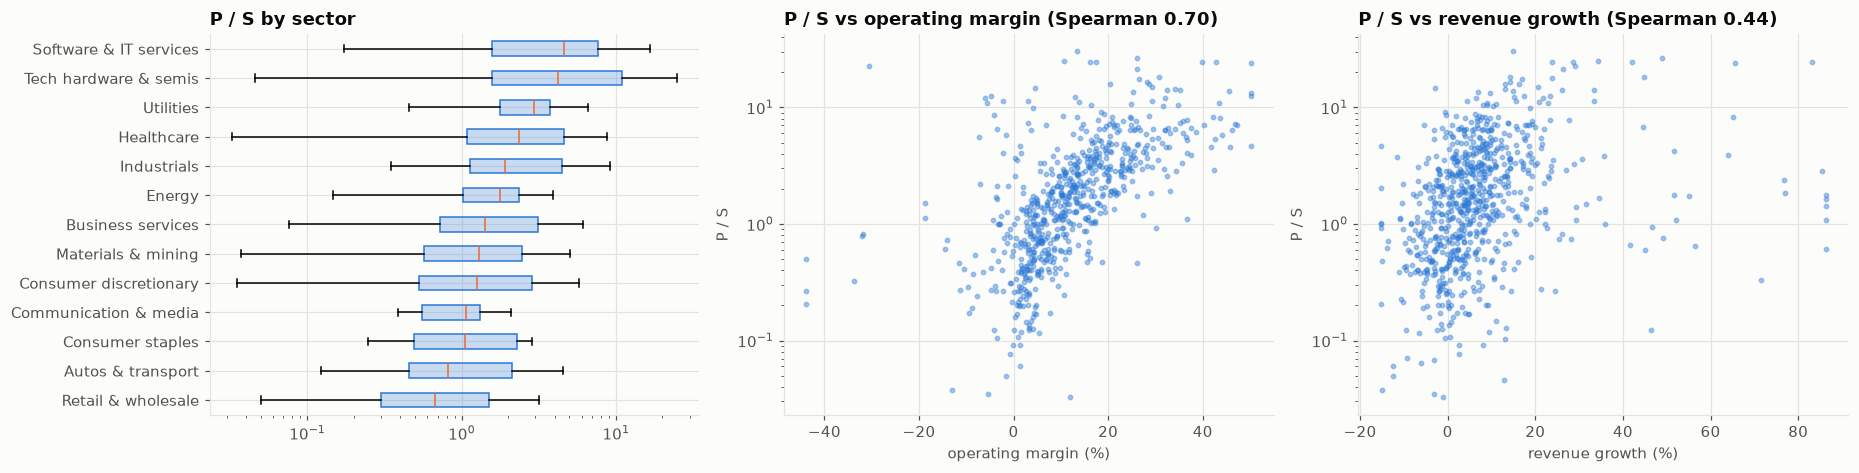

In [7]:
# --- Chart 1: the target and its relation to two key drivers
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
order = meta_now.groupby("sector")["target"].median().sort_values().index
axes[0].boxplot(
    [np.exp(meta_now.loc[meta_now["sector"] == s, "target"]) for s in order],
    tick_labels=order,
    orientation="horizontal",
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor=PALETTE[0] + "40", edgecolor=PALETTE[0]),
    medianprops=dict(color=PALETTE[1]),
)
axes[0].set_xscale("log")
axes[0].set_title("P / S by sector")
for ax, f in zip(axes[1:], ["operating margin", "revenue growth"]):
    ax.scatter(
        X_now[f] * 100,
        np.exp(meta_now["target"]),
        s=8,
        alpha=0.4,
        color=PALETTE[0],
    )
    ax.set_yscale("log")
    ax.set_xlabel(f"{f} (%)")
    ax.set_ylabel("P / S")
    rho = pd.Series(X_now[f]).corr(meta_now["target"], method="spearman")
    ax.set_title(f"P / S vs {f} (Spearman {rho:.2f})")
plt.tight_layout()
save_fig(fig, "01_multiples_by_sector")
plt.show()

## 6. Models and cross-validation

| Model | What it knows |
|---|---|
| **Sector median (comps)** | the median log P/S of the company's sector in the training fold |
| **OLS** | all features (median-imputed, plus missing flags) and sector dummies |
| **Elastic Net** | the same, with the penalty chosen by internal CV |
| **LightGBM** | raw features with missing values, sector as a categorical |

Two cross-validation schemes:

- **5-fold K-fold**, the situation of valuing a company whose peers are known;
- **leave-sector-out**, valuing a company in a sector the model has never seen, a stress test of how much the model relies on sector levels.

Errors are in log points. $e^{\text{MdAE}}-1$ is the typical percentage pricing error.

In [8]:
SECTORS = sorted(meta_now["sector"].unique())


def linear_design(X, meta, med=None):
    med = X.median() if med is None else med
    Xl = X.fillna(med)
    flags = X.isna().astype(float).add_suffix(" missing")
    dummies = (
        pd.get_dummies(meta["sector"])
        .reindex(columns=SECTORS, fill_value=0)
        .astype(float)
    )
    return pd.concat([Xl, flags, dummies], axis=1), med


def fit_predict(name, Xtr, mtr, ytr, Xte, mte):
    if name == "Sector median (comps)":
        med = pd.Series(ytr, index=mtr.index).groupby(mtr["sector"]).median()
        return mte["sector"].map(med).fillna(np.median(ytr)).to_numpy()
    if name in ("OLS", "Elastic Net"):
        A, medv = linear_design(Xtr, mtr)
        B, _ = linear_design(Xte, mte, medv)
        model = (
            make_pipeline(StandardScaler(), LinearRegression())
            if name == "OLS"
            else make_pipeline(
                StandardScaler(),
                ElasticNetCV(
                    l1_ratio=[0.2, 0.5, 0.9],
                    cv=5,
                    random_state=SEED,
                    max_iter=20_000,
                ),
            )
        )
        return model.fit(A, ytr).predict(B)
    if name == "LightGBM":
        A = Xtr.assign(
            sector=pd.Categorical(mtr["sector"], categories=SECTORS)
        )
        B = Xte.assign(
            sector=pd.Categorical(mte["sector"], categories=SECTORS)
        )
        model = lgb.LGBMRegressor(
            n_estimators=600,
            learning_rate=0.03,
            num_leaves=15,
            min_child_samples=15,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            random_state=SEED,
            verbose=-1,
        )
        return model.fit(A, ytr).predict(B)


MODELS = list(MODEL_COLORS)
y_now = meta_now["target"].to_numpy()
oof = {}
for scheme, splitter in {
    "5-fold": KFold(5, shuffle=True, random_state=SEED).split(X_now),
    "leave-sector-out": GroupKFold(len(SECTORS)).split(
        X_now, groups=meta_now["sector"]
    ),
}.items():
    splits = list(splitter)
    for name in MODELS:
        pred = np.full(len(y_now), np.nan)
        for tr, te in splits:
            pred[te] = fit_predict(
                name,
                X_now.iloc[tr],
                meta_now.iloc[tr],
                y_now[tr],
                X_now.iloc[te],
                meta_now.iloc[te],
            )
        oof[(scheme, name)] = pred


def score(pred):
    err = pred - y_now
    return {
        "MdAE (log pts)": np.median(np.abs(err)),
        "typical error %": (np.exp(np.median(np.abs(err))) - 1) * 100,
        "within ±30% %": (np.abs(err) < np.log(1.3)).mean() * 100,
        "R²": 1 - np.sum(err**2) / np.sum((y_now - y_now.mean()) ** 2),
    }


cv_table = pd.DataFrame({k: score(v) for k, v in oof.items()}).T
cv_table.index.names = ["scheme", "model"]
cv_table.round(3)

MdAE (log pts)  typical error %  \
scheme           model                                                    
5-fold           Sector median (comps)            0.73           108.52   
                 OLS                              0.43            53.84   
                 Elastic Net                      0.42            52.72   
                 LightGBM                         0.39            46.94   
leave-sector-out Sector median (comps)            0.85           133.95   
                 OLS                              0.48            61.30   
                 Elastic Net                      0.48            62.29   
                 LightGBM                         0.46            57.85   

                                        within ±30% %    R²  
scheme           model                                       
5-fold           Sector median (comps)          21.04  0.16  
                 OLS                            30.91  0.65  
                 Elastic Net                    32.34  0.66  
                 LightGBM                       35.45  0.72  
leave-sector-out Sector median (comps)          16.75 -0.05  
                 OLS                            31.69  0.59  
                 Elastic Net                    29.87  0.60  
                 LightGBM                       30.65  0.66

## 7. What drives the multiple: TreeSHAP

LightGBM's built-in TreeSHAP splits each company's predicted log multiple into additive feature contributions. The beeswarm-style chart shows each feature's contribution against its value, and the bar chart shows the mean absolute contribution.

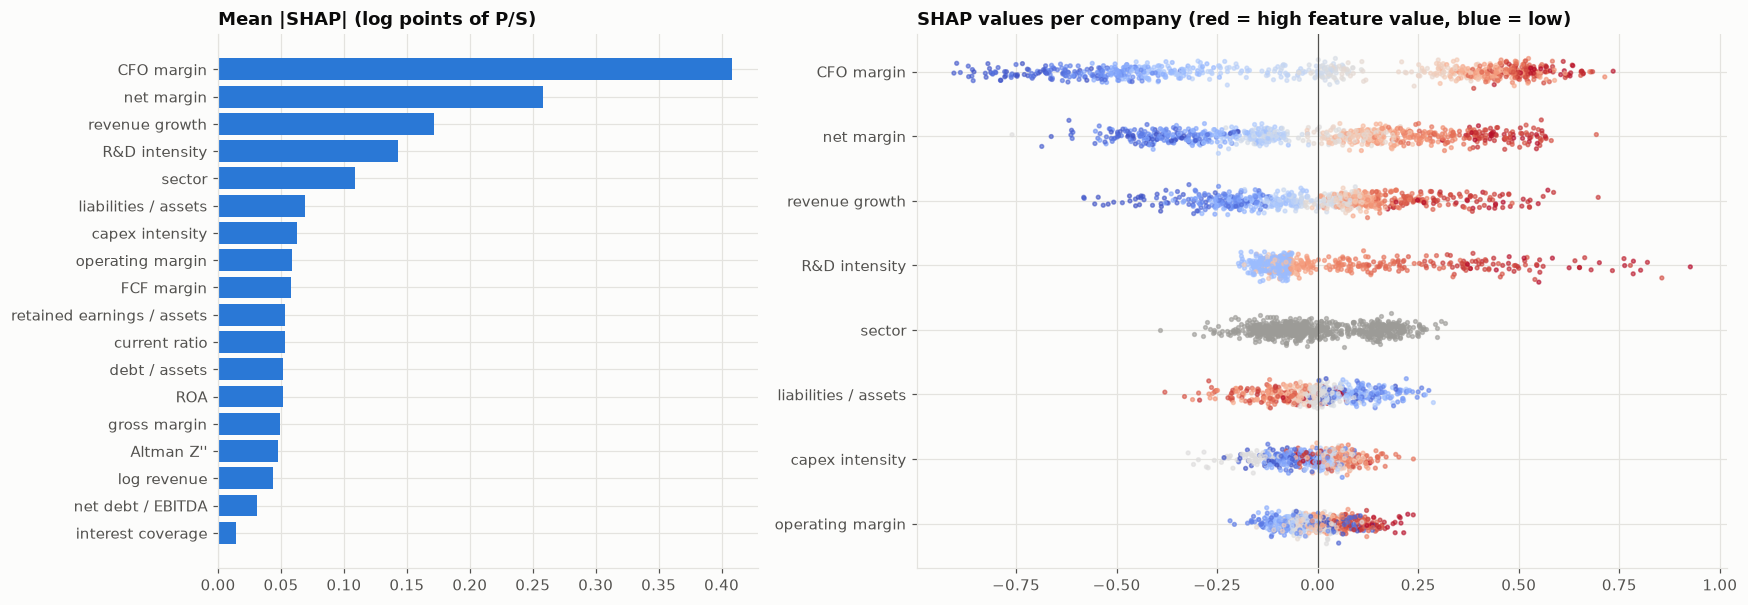

,CFO margin,net margin,revenue growth,R&D intensity,sector,liabilities / assets,capex intensity,operating margin,FCF margin,retained earnings / assets,current ratio,debt / assets,ROA,gross margin,Altman Z'',log revenue,net debt / EBITDA,interest coverage
mean |SHAP|,0.41,0.26,0.17,0.14,0.11,0.07,0.06,0.06,0.06,0.05,0.05,0.05,0.05,0.05,0.05,0.04,0.03,0.01


In [9]:
Xl_all = X_now.assign(
    sector=pd.Categorical(meta_now["sector"], categories=SECTORS)
)
gbm = lgb.LGBMRegressor(
    n_estimators=600,
    learning_rate=0.03,
    num_leaves=15,
    min_child_samples=15,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=SEED,
    verbose=-1,
).fit(Xl_all, y_now)
shap_vals = gbm.predict(Xl_all, pred_contrib=True)[:, :-1]
shap_df = pd.DataFrame(
    shap_vals, columns=FEATURES + ["sector"], index=X_now.index
)
imp = shap_df.abs().mean().sort_values()

fig, axes = plt.subplots(
    1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1, 1.5]}
)
axes[0].barh(imp.index, imp.values, color=PALETTE[0])
axes[0].set_title("Mean |SHAP| (log points of P/S)")
top = imp.index[::-1][:8]
for i, f in enumerate(top[::-1]):
    v = shap_df[f]
    if f == "sector":
        c = "#9c9b97"
    else:
        x = X_now[f]
        c = plt.cm.coolwarm(((x.rank(pct=True)).fillna(0.5)).to_numpy())
    axes[1].scatter(
        v,
        np.full(len(v), i) + np.random.default_rng(i).normal(0, 0.08, len(v)),
        c=c,
        s=6,
        alpha=0.6,
    )
axes[1].set_yticks(range(len(top)), top[::-1])
axes[1].axvline(0, color=INK_2, lw=0.8)
axes[1].set_title(
    "SHAP values per company (red = high feature value, blue = low)"
)
plt.tight_layout()
save_fig(fig, "02_shap")
plt.show()
imp.sort_values(ascending=False).round(3).to_frame("mean |SHAP|").T

## 8. Rich and cheap today

The residual is the actual log multiple minus the out-of-fold LightGBM prediction. A positive residual means the market pays more than the company's fundamentals and sector would suggest ("rich"), and a negative one means it pays less ("cheap"). For credit, a rich equity valuation means the equity cushion is partly sentiment, and a cheap one with a low Altman Z″ can be the market pricing distress that the accounts do not yet show.

In [10]:
best_model = cv_table.xs("5-fold")["MdAE (log pts)"].idxmin()
resid = pd.Series(
    y_now - oof[("5-fold", best_model)], index=meta_now.index, name="residual"
)
view = (
    meta_now[["ticker", "name", "sector"]]
    .assign(**{
        "P/S": np.exp(meta_now["target"]),
        "model P/S": np.exp(oof[("5-fold", best_model)]),
        "residual (log pts)": resid,
        "Altman Z''": X_now["Altman Z''"],
        "op. margin %": X_now["operating margin"] * 100,
        "rev. growth %": X_now["revenue growth"] * 100,
        "mkt cap $bn": meta_now["mcap"] / 1e9,
    })
    .set_index("ticker")
)
big = view[view["mkt cap $bn"] > 10]
print(
    f"Residuals from {best_model} (5-fold out-of-fold), companies above $10bn"
    " market cap"
)
pd.concat({
    "richest": big.nlargest(8, "residual (log pts)"),
    "cheapest": big.nsmallest(8, "residual (log pts)"),
}).round(2)

Residuals from LightGBM (5-fold out-of-fold), companies above $10bn market cap


name                  sector  \
         ticker                                                                
richest  FTAI                     FTAI AVIATION LTD.  Consumer discretionary   
         TSLA                            Tesla, Inc.       Autos & transport   
         FDXF    FedEx Freight Holding Company, Inc.       Autos & transport   
         TTWO    TAKE-TWO INTERACTIVE SOFTWARE, INC.  Software & IT services   
         XPO                               XPO, Inc.       Autos & transport   
         LITE                 Lumentum Holdings Inc.   Tech hardware & semis   
         SBUX                  Starbucks Corporation      Retail & wholesale   
         TLN                Talen Energy Corporation               Utilities   
cheapest EIX                    EDISON INTERNATIONAL               Utilities   
         FISV                           FISERV, INC.  Consumer discretionary   
         UAL          United Airlines Holdings, Inc.       Autos & transport   
         CF             CF INDUSTRIES HOLDINGS, INC.      Materials & mining   
         FSLR                      First Solar, Inc.   Tech hardware & semis   
         GM                   GENERAL MOTORS COMPANY       Autos & transport   
         QCOM                        QUALCOMM INC/DE   Tech hardware & semis   
         HUBS                          HubSpot, Inc.  Software & IT services   

                  P/S  model P/S  residual (log pts)  Altman Z''  \
         ticker                                                    
richest  FTAI    6.74       0.63                2.38         NaN   
         TSLA   14.77       1.76                2.13        4.46   
         FDXF    1.92       0.24                2.08         NaN   
         TTWO    5.77       1.05                1.71       -1.59   
         XPO     2.68       0.55                1.58         NaN   
         LITE   24.53       5.19                1.55       -1.60   
         SBUX    2.99       0.68                1.48       -0.37   
         TLN     6.59       1.54                1.46        0.06   
cheapest EIX     1.11       4.61               -1.42        0.93   
         FISV    1.19       4.58               -1.34        2.15   
         UAL     0.53       1.99               -1.33         NaN   
         CF      2.58       8.98               -1.25         NaN   
         FSLR    3.55      10.96               -1.13        6.97   
         GM      0.40       1.09               -1.00        1.32   
         QCOM    4.08      11.06               -1.00        5.59   
         HUBS    3.68       9.94               -0.99        2.26   

                 op. margin %  rev. growth %  mkt cap $bn  
         ticker                                            
richest  FTAI             NaN          44.53        16.89  
         TSLA            4.59          -2.93     1,400.98  
         FDXF            6.14          -1.09        16.93  
         TTWO           -1.57          18.16        38.38  
         XPO             8.04           1.05        21.86  
         LITE           17.41          83.22        73.92  
         SBUX            7.90           2.79       111.17  
         TLN            -3.49          22.03        17.00  
cheapest EIX            36.72           9.76        21.52  
         FISV           27.45           3.60        25.29  
         UAL             7.98           3.52        31.19  
         CF             32.47          19.34        18.29  
         FSLR           30.59          24.09        18.55  
         GM              1.57          -1.29        73.67  
         QCOM           27.90          13.66       180.72  
         HUBS            0.24          19.17        11.52

## 9. Did last year's cheap names outperform?

The model is refitted on **FY2024** fundamentals with prices at 30 April 2025, when the FY2024 10-Ks were public. Out-of-fold residuals are sorted into quintiles, and each quintile's equal-weighted total return over the next twelve months is measured. If residuals contain mispricing rather than missing fundamentals, the cheapest quintile should outperform.

The universe is today's ticker list, so companies delisted since April 2025 are missing (survivorship bias, which flatters every quintile similarly).

In [11]:
meta_bt, X_bt = build_panel(
    FY_BACKTEST,
    BACKTEST_PRICE_DATE,
    [f"CY{FY_BACKTEST + 1}Q1I", f"CY{FY_BACKTEST}Q4I"],
)
y_bt = meta_bt["target"].to_numpy()
pred_bt = np.full(len(y_bt), np.nan)
for tr, te in KFold(5, shuffle=True, random_state=SEED).split(X_bt):
    pred_bt[te] = fit_predict(
        best_model,
        X_bt.iloc[tr],
        meta_bt.iloc[tr],
        y_bt[tr],
        X_bt.iloc[te],
        meta_bt.iloc[te],
    )
p0 = prices.loc[:BACKTEST_PRICE_DATE].ffill().iloc[-1]
p1 = prices.loc[:BACKTEST_END_DATE].ffill().iloc[-1]
fwd = meta_bt["yahoo"].map(p1) / meta_bt["yahoo"].map(p0) - 1
bt = pd.DataFrame({
    "residual": y_bt - pred_bt,
    "fwd return": fwd,
    "sector": meta_bt["sector"],
}).dropna()
bt["quintile"] = pd.qcut(
    bt["residual"], 5, labels=["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 richest"]
)
# Sector-neutral version: rank residuals within each sector
bt["sector quintile"] = (
    bt.groupby("sector")["residual"].transform(
        lambda s: pd.qcut(s.rank(method="first"), 5, labels=False)
    )
    + 1
)
q_table = pd.DataFrame({
    "companies": bt.groupby("quintile", observed=True).size(),
    "mean fwd return %": (
        bt.groupby("quintile", observed=True)["fwd return"].mean() * 100
    ),
    "median fwd return %": (
        bt.groupby("quintile", observed=True)["fwd return"].median() * 100
    ),
    "sector-neutral mean %": (
        bt.groupby("sector quintile")["fwd return"]
        .mean()
        .set_axis(["Q1 cheapest", "Q2", "Q3", "Q4", "Q5 richest"])
        * 100
    ),
})
rho_bt = bt["residual"].corr(bt["fwd return"], method="spearman")
spread = (
    q_table.loc["Q1 cheapest", "mean fwd return %"]
    - q_table.loc["Q5 richest", "mean fwd return %"]
)
# Bootstrap the Q1–Q5 spread
rng = np.random.default_rng(SEED)
q1, q5 = (
    bt.loc[bt["quintile"] == "Q1 cheapest", "fwd return"].to_numpy(),
    bt.loc[bt["quintile"] == "Q5 richest", "fwd return"].to_numpy(),
)
boot = [
    rng.choice(q1, len(q1)).mean() - rng.choice(q5, len(q5)).mean()
    for _ in range(5_000)
]
print(
    f"FY{FY_BACKTEST} panel: {len(bt)} companies · rank IC of residual vs 12m"
    f" return {rho_bt:.3f} · Q1−Q5 spread {spread:.1f} pts (95% CI"
    f" {np.percentile(boot, 2.5) * 100:.1f} to"
    f" {np.percentile(boot, 97.5) * 100:.1f})"
)
q_table.round(1)

FY2024 panel: 759 companies · rank IC of residual vs 12m return -0.097 · Q1−Q5 spread 16.0 pts (95% CI -1.9 to 34.1)


,companies,mean fwd return %,median fwd return %,sector-neutral mean %
Q1 cheapest,152,50.00,30.00,43.70
Q2,152,38.70,24.20,40.90
Q3,151,34.20,18.80,37.00
Q4,152,38.80,18.20,38.40
Q5 richest,152,34.00,11.80,35.60


## 10. Results dashboard

In [12]:
dash = make_subplots(
    rows=2,
    cols=2,
    vertical_spacing=0.16,
    horizontal_spacing=0.1,
    subplot_titles=(
        "Typical out-of-fold pricing error (%)",
        "Actual vs model P/S (5-fold, log scale)",
        "Mean |SHAP| (log points)",
        f"12-month return by FY{FY_BACKTEST} residual quintile (%)",
    ),
)
for k, scheme in enumerate(["5-fold", "leave-sector-out"]):
    dash.add_trace(
        go.Bar(
            x=MODELS,
            y=[cv_table.loc[(scheme, m), "typical error %"] for m in MODELS],
            name=scheme,
            marker_color=[PALETTE[0], PALETTE[3]][k],
            text=[
                f"{cv_table.loc[(scheme, m), 'typical error %']:.0f}%"
                for m in MODELS
            ],
            textposition="outside",
        ),
        1,
        1,
    )
dash.add_trace(
    go.Scatter(
        x=view["model P/S"],
        y=view["P/S"],
        mode="markers",
        showlegend=False,
        marker=dict(size=5, color=PALETTE[0], opacity=0.5),
        text=view.index + " · " + view["sector"],
        hovertemplate=(
            "%{text}<br>model %{x:.2f}× · actual %{y:.2f}×<extra></extra>"
        ),
    ),
    1,
    2,
)
lims = [
    view[["P/S", "model P/S"]].min().min(),
    view[["P/S", "model P/S"]].max().max(),
]
dash.add_trace(
    go.Scatter(
        x=lims,
        y=lims,
        mode="lines",
        line=dict(color=INK_2, dash="dash"),
        showlegend=False,
    ),
    1,
    2,
)
dash.add_trace(
    go.Bar(
        y=imp.index,
        x=imp.values,
        orientation="h",
        marker_color=PALETTE[0],
        showlegend=False,
    ),
    2,
    1,
)
dash.add_trace(
    go.Bar(
        x=q_table.index.astype(str),
        y=q_table["mean fwd return %"],
        marker_color=PALETTE[2],
        name="mean return",
        text=q_table["mean fwd return %"].round(1),
        textposition="outside",
    ),
    2,
    2,
)
dash.add_trace(
    go.Bar(
        x=q_table.index.astype(str),
        y=q_table["sector-neutral mean %"],
        marker_color=PALETTE[6],
        name="sector-neutral",
    ),
    2,
    2,
)
dash.update_xaxes(type="log", row=1, col=2)
dash.update_yaxes(type="log", row=1, col=2)
b = cv_table.loc[("5-fold", best_model)]
c = cv_table.loc[("5-fold", "Sector median (comps)")]
dash.update_layout(
    height=950,
    width=1400,
    template="plotly_white",
    paper_bgcolor=SURFACE,
    plot_bgcolor=SURFACE,
    font=dict(color=INK_2),
    barmode="group",
    legend=dict(orientation="h", y=-0.06),
    margin=dict(t=130),
    title=dict(
        x=0.01,
        text=(
            f"<b>Fundamental valuation from SEC XBRL · FY{FY_NOW}, priced"
            f" {PRICE_DATE:%d %b %Y}</b><br><span"
            f" style='font-size:13px;color:{INK_2}'>{len(meta_now)} non-financial"
            f" companies · best model {best_model}: typical error"
            f" {b['typical error %']:.0f}% vs {c['typical error %']:.0f}% for"
            f" sector comps · FY{FY_BACKTEST} residual rank IC with 12m return"
            f" {rho_bt:.2f}</span>"
        ),
    ),
)
save_dashboard(dash, "dashboard")
cv_table.to_csv(OUT_DIR / "cv_scores.csv")
view.sort_values("residual (log pts)").to_csv(
    OUT_DIR / "valuation_residuals.csv"
)
q_table.to_csv(OUT_DIR / "backtest_quintiles.csv")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 11. Reading the results and limitations

FY2025 fundamentals, priced at the close of 16 October 2026, 770 U.S. non-financial companies:

**Fundamentals explain most of the cross-section; sector comps alone do not.** Sector-median P/S has a typical out-of-fold pricing error of 109% and an R² of 0.16. Adding fundamentals cuts the error to 53–54% for the linear models and to **47%** for LightGBM (R² 0.72; 35% of companies within ±30%).

Even the best model is off by about half for a typical company, which is the honest scale of "fair value" uncertainty from accounts alone.

- **The models do not just memorise sector levels.** When a whole sector is held out, sector comps collapse (R² −0.05) while LightGBM still reaches R² 0.66 with a 58% typical error. Margins and growth carry information that transfers across industries.
- **What the market pays for:** in the TreeSHAP attribution, cash-flow margin dominates (0.41 log points on average), followed by net margin, revenue growth and R&D intensity; sector adds 0.11. Leverage and the Altman Z″ matter little for the *equity* multiple, which is why they need their own credit models.
- **Rich and cheap names make economic sense, and show what the accounts miss.**
  - Among large caps, Tesla trades at 14.8× sales against 1.8× for its fundamentals, and Lumentum at 24.5× against 5.2×: growth or optionality the accounts do not show.
  - On the cheap side are Edison International (wildfire liabilities), Fiserv (after its 2025 guidance reset), United Airlines, GM and CF Industries: the market is pricing risks or cyclicality the latest year's margins do not capture.
  - For a credit analyst, "cheap" against fundamentals is a prompt to look for a liability or a business problem that has not yet hit the accounts, not a buy signal.

**Did last year's cheap names outperform?** Partly, and not robustly. On FY2024 fundamentals priced at 30 April 2025 (759 companies), the cheapest quintile returned 50% over the next twelve months and the richest 34%: a 16-point spread with a 95% bootstrap interval of −2 to +34 points, so not significant.

Within sectors the spread shrinks to 8 points. The rank correlation of the residual with forward returns is −0.10. The pattern also coincides with the rebound from the April 2025 tariff sell-off, which favoured beaten-down cyclicals. Survivorship bias (today's ticker list) lifts all quintiles.

**The ETL is the hard part.** Revenue alone comes under three main tags. Debt is missing for about half of filers, which is why EV/Sales was dropped. ADRs (H World, New Oriental, NetEase, Trip.com) had to be excluded because their cover-page share counts are in ordinary shares and some report in local currency: in a first pass they showed up as the "richest" and "cheapest" companies in the market.

Every valuation model built from raw XBRL needs these checks before its residuals mean anything.

**Limitations**

- One cross-section and one forward year. A proper test of residual-based value needs many years of point-in-time fundamentals and filing dates.
- Frames map fiscal years to calendar periods, and the balance sheet can come from a later 10-Q than the income statement. Multi-class share counts (for example Alphabet) are incomplete in the cover-page data, so those companies drop out or are mis-scaled.
- The SIC-to-sector mapping is coarse (for example, an aircraft-leasing company falls under services). GICS-style classifications would sharpen the comps baseline.

## References

### Finance and regulation

- Liu, J., Nissim, D., & Thomas, J. (2002). Equity valuation using multiples. *Journal of Accounting Research, 40*(1), 135–172. https://doi.org/10.1111/1475-679X.00042
- Alford, A. W. (1992). The effect of the set of comparable firms on the accuracy of the price-earnings valuation method. *Journal of Accounting Research, 30*(1), 94–108. https://doi.org/10.2307/2491093
- Bhojraj, S., & Lee, C. M. C. (2002). Who is my peer? A valuation-based approach to the selection of comparable firms. *Journal of Accounting Research, 40*(2), 407–439. https://doi.org/10.1111/1475-679X.00054
- Altman, E. I. (1968). Financial ratios, discriminant analysis and the prediction of corporate bankruptcy. *The Journal of Finance, 23*(4), 589–609. https://doi.org/10.1111/j.1540-6261.1968.tb00843.x

### Machine learning and deep learning

- Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B, 67*(2), 301–320. https://doi.org/10.1111/j.1467-9868.2005.00503.x
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., … Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9
- Raasveldt, M., & Mühleisen, H. (2019). DuckDB: An embeddable analytical database. In *Proceedings of the 2019 International Conference on Management of Data*. https://doi.org/10.1145/3299869.3320212